# A1 Baselines (Stage 8) and linear models (Track T1)

Every advanced model in the project is reported as an improvement over these baselines.

- **Target:** B1's health score (`src/targets.py`), in **forecasting mode (Option A, §7.2)**: predict Health(t + 1 h) from information at time t. The 1-hour lead is taken on the full 15-min grid and kept only when the row 4 bins ahead is exactly 1 hour later, so it never jumps overnight.
- **Regression:** (a) persistence, Health(t+1h) = Health(t); (b) Ridge.
- **Classification:** (a) majority class; (b) rule: the status implied by Health(t); (c) Logistic Regression with `class_weight="balanced"`.
- **Tuning:** GridSearchCV over a 5-fold `TimeSeriesSplit`, training period only. Scaler and mean-imputation are fitted on training data only.
- **Evaluation:** train / val / test, the test year split at the **2023-02-14 irradiance sensor change**, and the unseen inverters.

All code is in `src/models/linear.py`; this notebook only calls it.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
import matplotlib.pyplot as plt
import pandas as pd
from src import eda
from src.models import linear

pd.set_option("display.width", 160)
eda.set_style()
out = linear.run(log=False)   # set log=True once for the final run to append to results/results.csv
results = out["results"]

  train               270,448 rows
  val                 190,158 rows
  test                464,676 rows
  test_before_14feb    35,860 rows
  test_after_14feb    428,816 rows
  test_unseen          46,980 rows


Tuning Ridge ...


  best alpha = 1000.0
Tuning Logistic Regression ...


  best C = 1000


## Data and tuning

In [2]:
print("Features:", linear.FEATURES)
print("Best Ridge alpha:", out["ridge"].best_params_["model__alpha"])
print("Best Logistic C: ", out["logit"].best_params_["model__C"])
pd.DataFrame(out["ridge"].cv_results_)[["param_model__alpha", "mean_test_score", "std_test_score"]]

Features: ['health_now', 'n_valid_5min', 'irradiance_wm2', 'temp_c', 'rh_pct', 'wind_speed_ms', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'capacity_kwp', 'tilt_deg', 'altitude_m', 'orient_south', 'orient_east_west', 'orient_mixed']
Best Ridge alpha: 1000.0
Best Logistic C:  1000


,param_model__alpha,mean_test_score,std_test_score
0,0.01,-11.521587,1.593639
1,0.10,-11.521584,1.593638
2,1.00,-11.521553,1.593627
3,10.00,-11.521246,1.593518
4,100.00,-11.518256,1.592457
5,1000.00,-11.495631,1.584625
6,10000.00,-11.518089,1.602577
7,100000.00,-13.326580,2.557704
8,1000000.00,-19.224808,2.895745


Ridge's CV RMSE is flat up to alpha = 1000, then gets worse, so 1000 is a real optimum inside the grid. Logistic macro-F1 is flat for every C >= 1, so regularisation barely matters: with 270k rows and 16 features, a linear model has little room to overfit.

## Regression: persistence vs Ridge

In [3]:
reg = results[results["task"] == "regression"]
reg.pivot(index="split", columns="model", values="rmse").loc[list(out["parts"])]

model,Persistence,Ridge
split,,
train,12.135,10.836
val,12.924,11.875
test,16.563,17.376
test_before_14feb,10.878,11.218
test_after_14feb,16.952,17.794
test_unseen,17.139,15.995


**Finding.**
- Ridge beats persistence on **train (10.8 vs 12.1 RMSE) and validation (11.9 vs 12.9)**, so it does learn something beyond "tomorrow equals today".
- On the **test year it is worse (17.4 vs 16.6)**. The damage is concentrated after 2023-02-14: before the sensor change both are close to their validation level (about 11 RMSE), and after it both degrade (17.0 and 17.8).
- Train, validation and pre-change test scores are close, so there is no sign of overfitting. The test drop is distribution shift caused by the sensor, not the model.

## Classification: majority, rule, Logistic Regression

In [4]:
cls = results[results["task"] == "classification"]
order = list(out["parts"])
pd.concat({m: cls[cls["model"] == m].set_index("split").loc[order, ["macro_f1", "faulty_recall", "faulty_precision"]]
           for m in cls["model"].unique()}, axis=1)

Majority class                                Rule: status of Health(t)                                Logistic Regression                \
                        macro_f1 faulty_recall faulty_precision                  macro_f1 faulty_recall faulty_precision            macro_f1 faulty_recall   
split                                                                                                                                                        
train                     0.3010           0.0              0.0                    0.6154        0.6802           0.6426              0.6070        0.6759   
val                       0.2893           0.0              0.0                    0.6290        0.7403           0.6519              0.6228        0.7300   
test                      0.0988           0.0              0.0                    0.6492        0.7684           0.7266              0.5491        0.7082   
test_before_14feb         0.2965           0.0              0.0                    0.6855        0.7740           0.7550              0.6771        0.7504   
test_after_14feb          0.0723           0.0              0.0                    0.5849        0.7683           0.7261              0.4859        0.7073   
test_unseen               0.0974           0.0              0.0                    0.5428        0.6442           0.5773              0.4155        0.6068   

                                    
                  faulty_precision  
split                               
train                       0.7110  
val                         0.6869  
test                        0.6214  
test_before_14feb           0.7942  
test_after_14feb            0.6186  
test_unseen                 0.3996

**Finding.**
- **Majority class** gets macro-F1 0.30 on train but 0.10 on test, with Faulty recall 0. The test year's class mix flips (most post-February rows are labelled Faulty), so "always Healthy" collapses. This is why accuracy is never reported on its own.
- **Rule (status of Health(t))** is the strongest baseline: test macro-F1 **0.65**, Faulty recall **0.77**.
- **Logistic Regression** matches the rule before the sensor change (0.68 vs 0.69 macro-F1) but falls further after it (0.49 vs 0.58). Its weights on irradiance and time features were learned on the old sensor scale.
- Every model is worse on the **unseen inverters** (rule 0.54, Logistic 0.42 macro-F1). These are mostly new installations from 2023, so they carry both the station shift and the sensor shift.

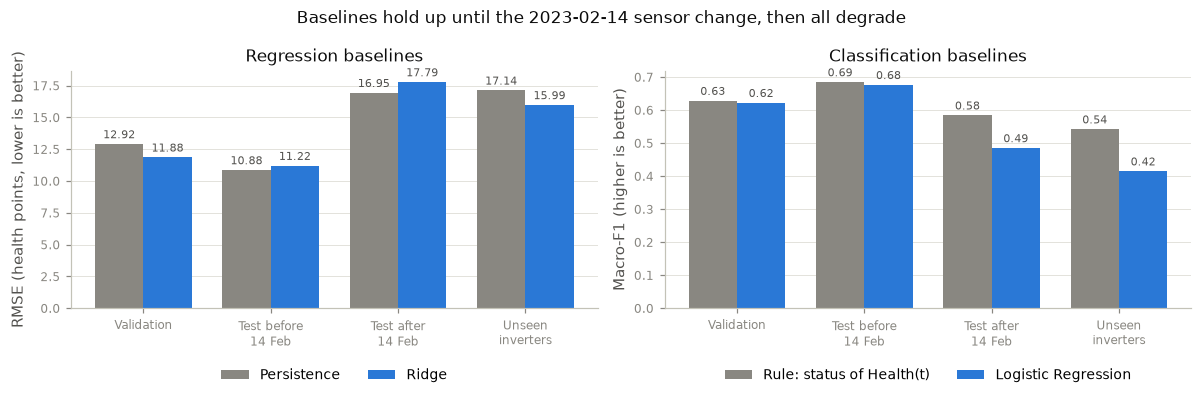

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
splits = ["val", "test_before_14feb", "test_after_14feb", "test_unseen"]
labels = ["Validation", "Test before\n14 Feb", "Test after\n14 Feb", "Unseen\ninverters"]
x = range(len(splits))
for ax, (task, metric, ylabel, models) in zip(axes, [
        ("regression", "rmse", "RMSE (health points, lower is better)", ["Persistence", "Ridge"]),
        ("classification", "macro_f1", "Macro-F1 (higher is better)", ["Rule: status of Health(t)", "Logistic Regression"])]):
    width = 0.38
    for i, (model, colour) in enumerate(zip(models, [eda.MUTED, eda.BLUE])):
        r = results[(results["task"] == task) & (results["model"] == model)].set_index("split").loc[splits, metric]
        bars = ax.bar([xi + (i - 0.5) * width for xi in x], r, width=width, color=colour, label=model)
        ax.bar_label(bars, fmt="%.2f", fontsize=7, color=eda.INK_2, padding=2)
    ax.set_xticks(list(x))
    ax.set_xticklabels(labels)
    ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
axes[0].set_title("Regression baselines")
axes[1].set_title("Classification baselines")
fig.suptitle("Baselines hold up until the 2023-02-14 sensor change, then all degrade", color=eda.INK, fontsize=11)
fig.tight_layout()
eda.save(fig, "a1_baselines_by_split");

## Explainability: coefficients

Coefficients are on the standardised scale (each feature scaled to unit variance on train), so their sizes can be compared directly.

In [6]:
out["coef_ridge"].sort_values("coef", key=abs, ascending=False).round(3)

,coef
health_now,13.638
n_valid_5min,6.227
day_cos,-0.911
hour_sin,0.910
altitude_m,0.833
tilt_deg,0.748
temp_c,-0.663
rh_pct,0.399
orient_mixed,-0.382
day_sin,-0.324


In [7]:
out["coef_logit"].round(3)

,Faulty,Healthy,Warning
health_now,-1.021,1.305,-0.284
n_valid_5min,-0.367,-0.280,0.647
irradiance_wm2,0.095,0.031,-0.126
temp_c,0.270,-0.332,0.062
rh_pct,0.036,-0.119,0.083
wind_speed_ms,0.012,-0.040,0.028
hour_sin,-0.141,0.081,0.060
hour_cos,0.144,-0.132,-0.012
day_sin,0.071,-0.109,0.038
day_cos,0.264,-0.277,0.014


**Finding.**
- Ridge is dominated by **`health_now`** (13.6) and **`n_valid_5min`** (6.2); every other feature is below 1. The linear model is mostly persistence plus a data-completeness correction.
- `orient_south` and `orient_east_west` have coefficients of exactly 0 because they are constant in our data: every azimuth string falls into "other" or "mixed" in `src/features.py`. That is a feature issue for B2, not a model property.


## Default vs tuned hyperparameters (Stage 10)

In [8]:
out["tuning"]

,model,version,params,val_rmse,test_rmse,val_macro_f1,val_faulty_recall,test_macro_f1,test_faulty_recall
0,Ridge,default,1.0,11.864,17.332,NaN,NaN,NaN,NaN
1,Ridge,tuned,1000.0,11.875,17.376,NaN,NaN,NaN,NaN
2,Logistic Regression,default,1.0,NaN,NaN,0.6228,0.73,0.5491,0.7082
3,Logistic Regression,tuned,1000,NaN,NaN,0.6228,0.73,0.5491,0.7082


**Finding.** Tuning makes almost no difference:
- Ridge val RMSE is 11.86 with the default alpha = 1 and 11.88 with alpha = 1000.
- Logistic Regression gives identical scores for C = 1 and C = 1000.

With 270k rows and 16 features a linear model has very little variance to regularise away, so the regularisation strength hardly matters. This is reported honestly as a result, not hidden. More capacity (non-linear models) is what could help, not more tuning.

## Permutation importance (validation sample, 20,000 rows)

How much the score gets worse when one feature is shuffled: RMSE increase for Ridge, macro-F1 drop for Logistic. Unlike coefficients, this measures what the model actually relies on for prediction.

In [9]:
out["importance"]

,Ridge,Logistic Regression
health_now,13.6823,0.2656
n_valid_5min,3.1668,0.0039
altitude_m,0.1227,0.0137
hour_sin,0.0982,0.0161
day_cos,0.0978,0.0400
orient_mixed,0.0416,0.0345
temp_c,0.0230,0.0325
rh_pct,0.0112,0.0043
irradiance_wm2,0.0056,0.0090
day_sin,0.0022,0.0026


**Finding.**
- Both models rely almost entirely on **`health_now`**: shuffling it adds 13.7 RMSE points to Ridge and costs Logistic 0.27 macro-F1.
- For Ridge, **`n_valid_5min`** is second (+3.2 RMSE): bins with fewer valid readings are more likely to be followed by an outage.
- Every other feature adds less than 0.13 RMSE. Weather, time and metadata carry almost no extra forecasting information for a linear model 1 hour ahead.
- This confirms the coefficient reading: the linear models are mostly persistence plus a data-completeness correction.

## Failure cases (largest Ridge errors)

In [10]:
pd.concat(out["failures"], names=["split"])

inverter_id                time  health_now  health_lead  predicted  abs_error  irradiance_wm2  n_valid_5min  temp_c
split                                                                                                                                
val   0  sq_block_r_inverter 2022-08-12 08:30:00       100.0          0.0     101.41     101.41          114.12             3   25.45
      1  sq_block_s_inverter 2022-08-12 08:30:00       100.0          0.0     101.41     101.41          114.12             3   25.45
      2     zone_j2_inverter 2022-08-03 09:30:00       100.0          0.0     101.13     101.13          152.20             3   27.28
test  0    zone_d_inverter_2 2023-06-25 09:00:00       100.0          0.0     101.51     101.51          902.99             3   30.22
      1     zone_a7_inverter 2023-05-04 12:30:00       100.0          0.0     101.03     101.03          787.33             3   27.76
      2     zone_a7_inverter 2023-05-04 12:45:00       100.0          0.0     101.01     101.01          783.71             3   27.33

**Finding.** All 6 worst errors (3 in validation, 3 in test) have the same shape: **health is 100 at time t and 0 one hour later**, with normal irradiance and complete data at t. These are **outage onsets**:
- **Zone J2, 2022-08-03 09:30:** the start of its 36-day outage, the longest gap in the A1 EDA.
- **Zone A7, 2023-05-04 12:30-12:45:** the start of the 12-day outage shared with Zone J1 (also in the EDA gap list).
- **SQ Block R and SQ Block S, 2022-08-12 08:30:** both fail in the same bin, which suggests a shared communication outage.

Health is 0 there because `src/targets.py` fills missing power with 0, so an outage is scored as "Faulty". Nothing at time t announces an outage an hour later, so **no model using only data at time t can predict these**. They will limit every team model, not just the linear ones.

Ridge also predicts slightly above 100 (101.4). Clipping predictions to the 0-100 range is a possible small improvement, left for the team to decide.

## Summary

| Model | Task | Val | Test | Test before / after 14 Feb | Unseen |
|---|---|---|---|---|---|
| Persistence | RMSE | 12.92 | 16.56 | 10.88 / 16.95 | 17.14 |
| Ridge (alpha = 1000) | RMSE | 11.88 | 17.38 | 11.22 / 17.79 | 16.00 |
| Majority class | macro-F1 | 0.29 | 0.10 | 0.30 / 0.07 | 0.10 |
| Rule: status of Health(t) | macro-F1 | 0.63 | 0.65 | 0.69 / 0.58 | 0.54 |
| Logistic Regression | macro-F1 | 0.62 | 0.55 | 0.68 / 0.49 | 0.42 |

- Tuning barely matters (default and tuned are within 0.02 RMSE).
- Both linear models rely on `health_now`, then `n_valid_5min`.
- The worst errors are all unpredictable outage onsets.

**For the team:**
1. These baselines use B1's target exactly as it is. The labels are distorted after 2023-02-14 (the sensor change), so **all test-year numbers, including other models', are not yet trustworthy**. Re-run with `python -m src.models.linear` once the target is fixed.
2. Any model must beat **persistence (val RMSE 12.9)** and the **rule baseline (val macro-F1 0.63, Faulty recall 0.74)** to add value.
3. Numbers are not comparable with the current MLP results in `results.csv`. Those predict Health(t) from features that include the target's own inputs at time t (§7.2 leakage), not Health(t+1h).